# Project 2

Welcome to the second NLP1 project. The goal of the second tutorial was to get you familiar with using pre-trained embeddings and moving towards a compositional encoder for text classification.

Given the skills you have developed in the last week, you will now be applying them within the dataset and task you have chosen during Project 1. You will be applying hands-on the experiments you have already explored in the Tutorial 2, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and errors analyses, and tackling your own research questions. 


The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

# Get to work!

1. Find a word embedding model that is appropriate for your dataset. Think about the language, the kind of text you are working with. Find evidence that your choice is a good one: 
    * Can you tokenize your texts in a way coherent with the definition of a token in the embedding model?
    * Does the model's vocabulary give enough coverage to the words in your texts? etc.
2. Explore what your chosen word embedding model captures. Some things you might consider: 
    * Is it good at representing interesting similarities (re to your choice of task)? J
    * Have you found task-specific evidence that it's better than some other reasonable alternative?
    * Do you know about limitations of this model?
    * Any limitations that you find particularly troubling for your task? 
3. Experiment with the embed-and-pool approach.  
    * What design choices have meaningful impact in classification performance (eg, embedding size, architecture design, optimisation parameters), if any?
    * Is this better than what you could achieve last week? In other words, did pretrained embeddings add to your design?
4. Experiment with a recurrent encoder (GRU or LSTM). 
    * What design choices have meaningful impact in classification performance, if any?
    * Did you investigate the impact of data size, embedding parameters (trained or not, fixed or trainable, etc)?
    * Did you struggle with over-fitting?
    * How far can this approach go? Are you able to improve meaningfully on embed-and-pool?
5. We make decisions under uncertainty all the time, are you gathering enough information to substantiate your choices? Various things can lead to small differences in results, and these differences are not always consistent. Here are some things to think about:
    * How did you structure you hyperparameter search?
    * Are you keeping an eye on experimental variance?
6. Experiment with error analysis and try to discover what characteristics of input texts are predictive of performance differences across major design choices. 
    * What analysis features did you come up with?
    * Which ones did you manage to test and how did that go?
    * What would you prioritise in the future in order to improve your systems?

Be mindful that you will be using your experiments to write up your final blog, so make sure your code is clean and neat!

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

# Tips

## Pretrained embedding models

We will post a list with some options for you. 

## Features for analysis

Features that you can interpret as an aspect of _complexity_ in light of your task's goals.

- length
- presence of rare/common words, including unknown words
- syntactic features (like parts-of-speech, syntactic complexity, syntactic voice, presence of negation, etc.)
- semantic features (eg, the average similarity of the text to training documents or some curated set of training documents, presence of words in certain semantic classes, etc.)
- task-specific features (eg, 
- model-specific features (eg, predicted label, probability assigned to predicted label, number of parameters or layers or some other model descriptor)

# Dataset and task

We continue with the English six-way emotion-classification task selected in Project 1. The data come from `dair-ai/emotion`, and the labels are sadness, joy, love, anger, fear, and surprise. The original validation split is merged into the training data; the original test split remains untouched until final evaluation.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# The notebook is intended to run from the part2 directory.
root = Path.cwd().parent
sys.path.insert(0, str(root))

import part1

In [2]:
from datasets import concatenate_datasets, load_dataset

outcome_space = part1.clslib.NamedClasses(
    ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']
)

dataset = load_dataset("dair-ai/emotion", "split")
dataset["train"] = concatenate_datasets(
    [dataset["train"], dataset["validation"]]
)
del dataset["validation"]

print(outcome_space)
print(dataset)

0: sadness, 1: joy, 2: love, 3: anger, 4: fear, 5: surprise
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 18000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})


In [3]:
for index in [0, 2]:
    example = dataset["train"][index]
    print(f"Text: {example['text']}")
    print(f"Gold label (id): {example['label']}")
    print(f"Gold label (name): {outcome_space.name(example['label'])}\n")

Text: i didnt feel humiliated
Gold label (id): 0
Gold label (name): sadness

Text: im grabbing a minute to post i feel greedy wrong
Gold label (id): 3
Gold label (name): anger



## Class distributions

The class distribution is imbalanced: joy and sadness are the largest classes, while surprise is the smallest. This motivates reporting macro-F1 in addition to accuracy.

---- train set (N=18000) ----
Sadness: 5216 examples (28.98%)
Joy: 6066 examples (33.70%)
Love: 1482 examples (8.23%)
Anger: 2434 examples (13.52%)
Fear: 2149 examples (11.94%)
Surprise: 653 examples (3.63%)


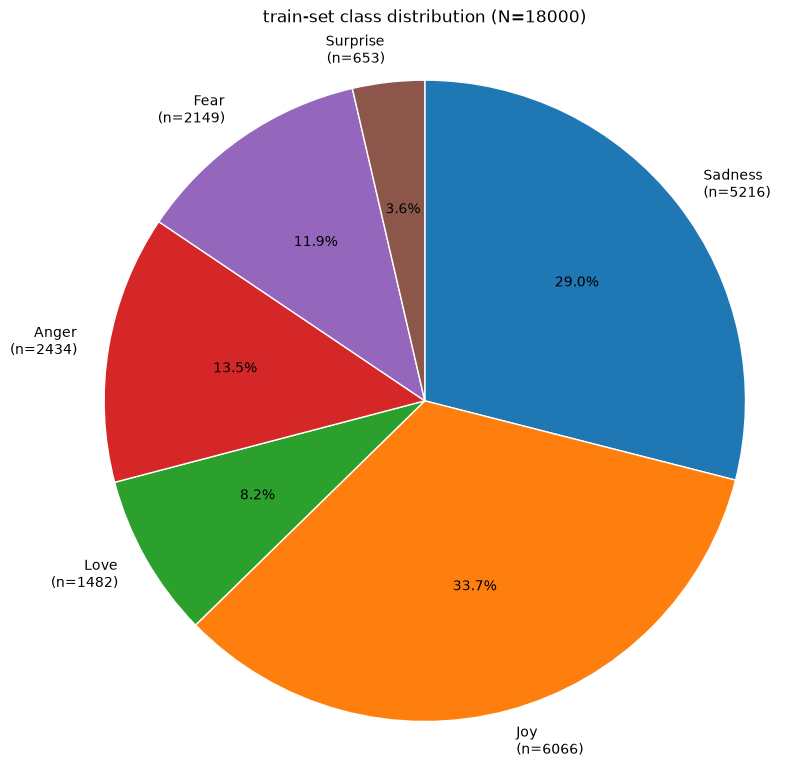

---- test set (N=2000) ----
Sadness: 581 examples (29.05%)
Joy: 695 examples (34.75%)
Love: 159 examples (7.95%)
Anger: 275 examples (13.75%)
Fear: 224 examples (11.20%)
Surprise: 66 examples (3.30%)


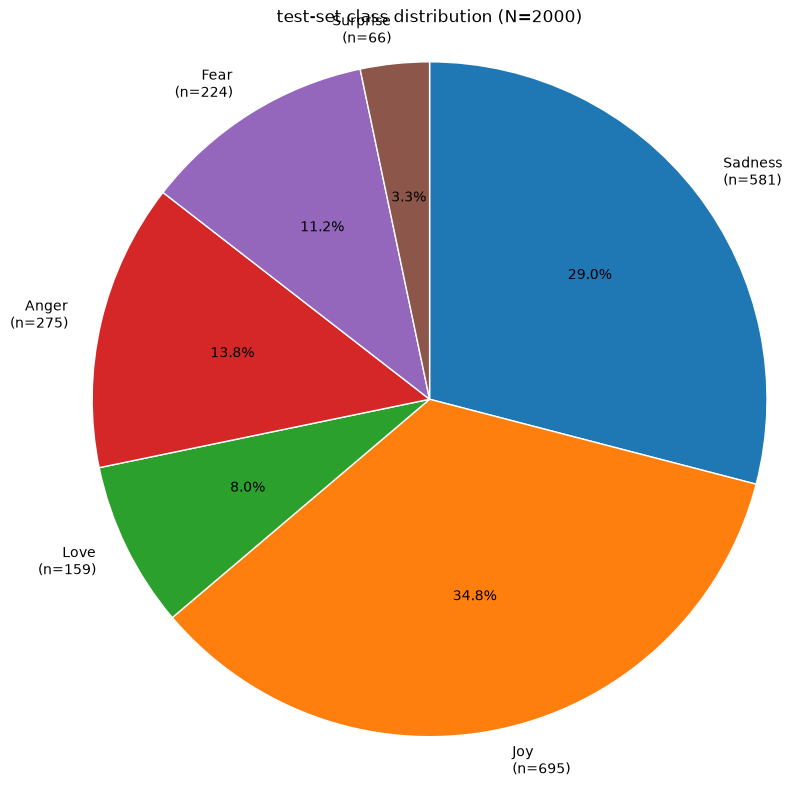

In [4]:
for split_name in ["train", "test"]:
    labels = np.asarray(dataset[split_name]["label"])
    class_counts = np.bincount(labels, minlength=len(outcome_space))
    class_percentages = 100 * class_counts / labels.size

    print(f"---- {split_name} set (N={labels.size}) ----")
    for label_id, label_name in enumerate(outcome_space.names):
        print(
            f"{label_name.title()}: {class_counts[label_id]} examples "
            f"({class_percentages[label_id]:.2f}%)"
        )

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.pie(
        class_counts,
        labels=[
            f"{name.title()}\n(n={count})"
            for name, count in zip(outcome_space.names, class_counts)
        ],
        autopct="%1.1f%%",
        startangle=90,
        counterclock=False,
        wedgeprops={"edgecolor": "white", "linewidth": 1},
    )
    ax.set_title(f"{split_name}-set class distribution (N={labels.size})")
    ax.axis("equal")
    plt.tight_layout()
    plt.show()

## Text-length distributions

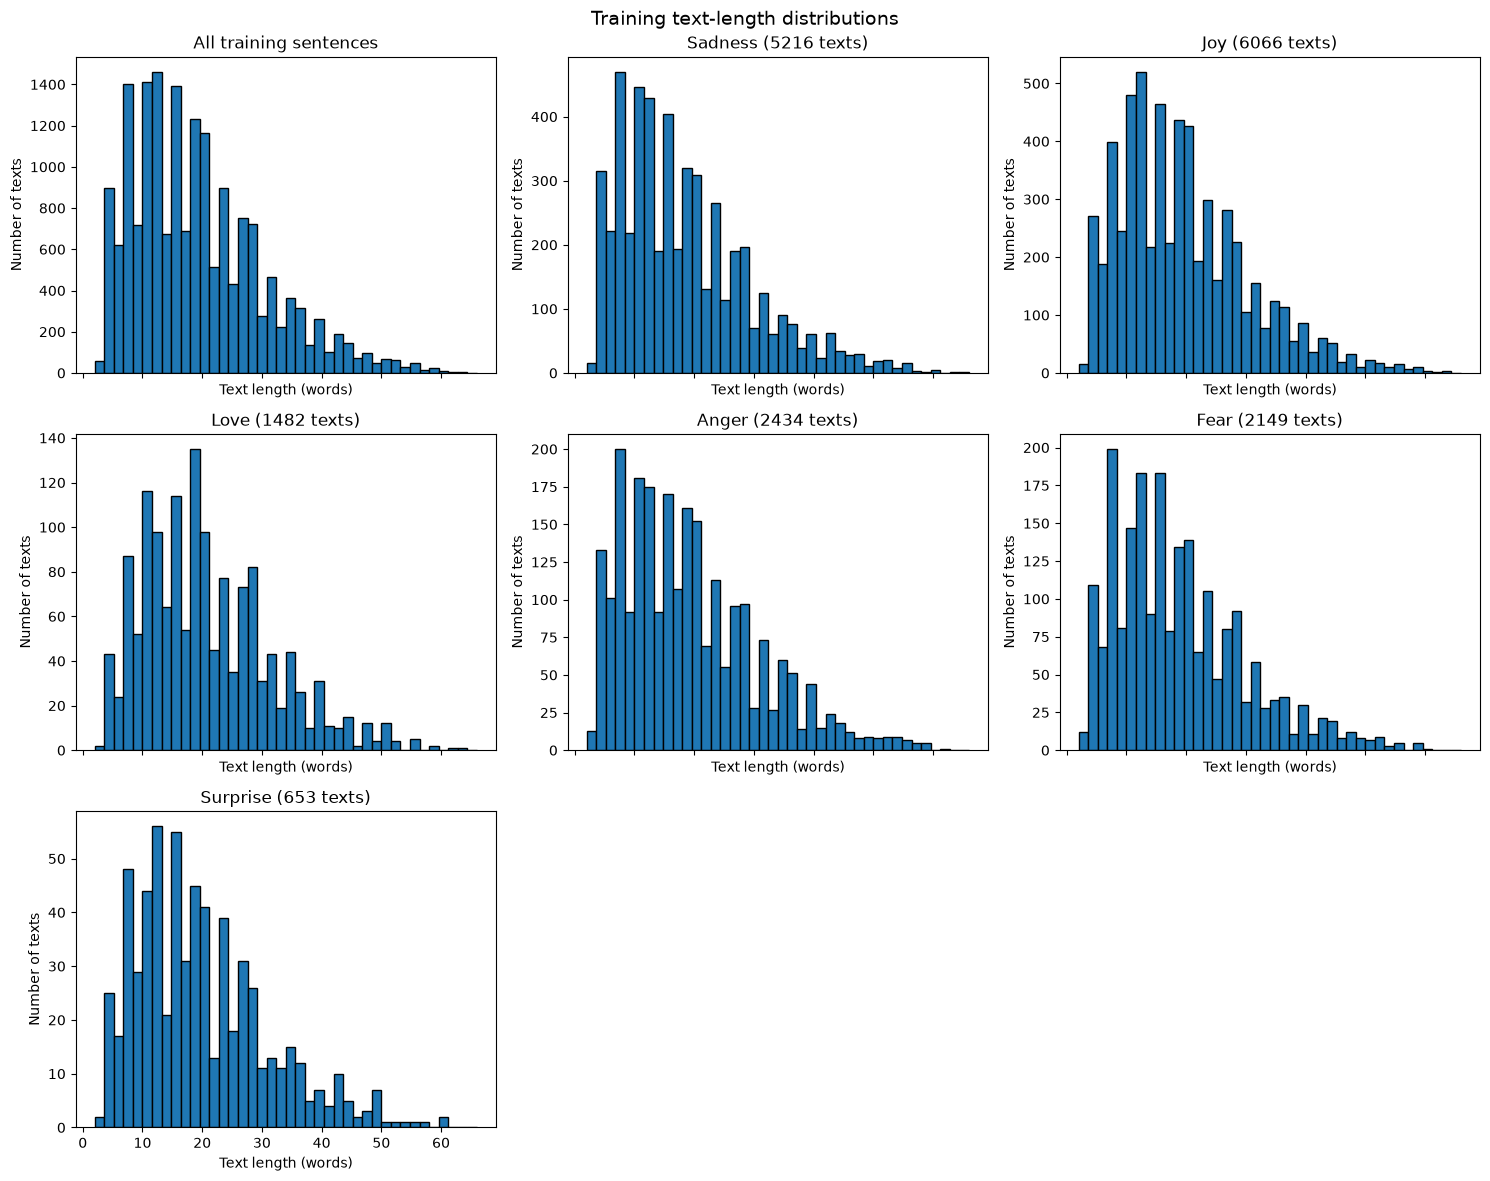

In [5]:
import math

train_texts = dataset["train"]["text"]
train_labels = np.asarray(dataset["train"]["label"])
text_lengths = np.asarray([len(text.split()) for text in train_texts])

num_plots = len(outcome_space) + 1
ncols = 3
nrows = math.ceil(num_plots / ncols)
fig, axes = plt.subplots(
    nrows=nrows, ncols=ncols, figsize=(5 * ncols, 4 * nrows), sharex=True
)
axes = np.atleast_1d(axes).flatten()
bin_edges = np.histogram_bin_edges(text_lengths, bins=40)

axes[0].hist(text_lengths, bins=bin_edges, edgecolor="black")
axes[0].set_title("All training sentences")
axes[0].set_xlabel("Text length (words)")
axes[0].set_ylabel("Number of texts")

for label_id, label_name in enumerate(outcome_space.names):
    class_lengths = text_lengths[train_labels == label_id]
    axis = axes[label_id + 1]
    axis.hist(class_lengths, bins=bin_edges, edgecolor="black")
    axis.set_title(f"{label_name.title()} ({len(class_lengths)} texts)")
    axis.set_xlabel("Text length (words)")
    axis.set_ylabel("Number of texts")

for axis in axes[num_plots:]:
    axis.set_visible(False)

fig.suptitle("Training text-length distributions", fontsize=14)
plt.tight_layout()
plt.show()

# Get to Work 1: Choosing a pretrained embedding model

Project 1 already established the dataset, a lowercase word-level tokenization procedure, and working loaders for GloVe embeddings. We transfer those components here as the starting point for selecting the Project 2 embedding model.

The dataset is English and consists of short, informal, first-person texts. We therefore consider two existing candidates: GloVe 6B, trained on Wikipedia and Gigaword, and GloVe Twitter 27B, trained on Twitter data. The Twitter model is intuitively better matched to forms such as `im` and `didnt`, but vocabulary coverage and task evidence still need to confirm that intuition.

## Word-level tokenization

The tokenizer lowercases the input and separates words and punctuation before vocabulary lookup. This produces word-like units compatible with the word-level entries used by GloVe. The 1,000-token cap is inherited from Project 1 and will need to be reconsidered when measuring embedding coverage.

In [6]:
from tokenizers import Tokenizer
from tokenizers.models import WordLevel
from tokenizers.normalizers import Lowercase
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.trainers import WordLevelTrainer

vocab_size = 1000
min_frequency = 2
unk_token = "??"

tokenizer = Tokenizer(WordLevel(unk_token=unk_token))
tokenizer.normalizer = Lowercase()
tokenizer.pre_tokenizer = Whitespace()
trainer = WordLevelTrainer(
    vocab_size=vocab_size,
    min_frequency=min_frequency,
    special_tokens=[unk_token],
)
tokenizer.train_from_iterator(train_texts, trainer=trainer)

example_text = train_texts[0]
example_encoding = tokenizer.encode(example_text)
print("Original text:", example_text)
print("Tokens:", example_encoding.tokens)
print("Token IDs:", example_encoding.ids)

Original text: i didnt feel humiliated
Tokens: ['i', 'didnt', 'feel', 'humiliated']
Token IDs: [1, 139, 2, 659]


Unique normalized training tokens: 16,196


Tokens occurring at least 2 times: 7,902
Learned vocabulary size: 1,000
Eligible tokens excluded by the cap: 6,903


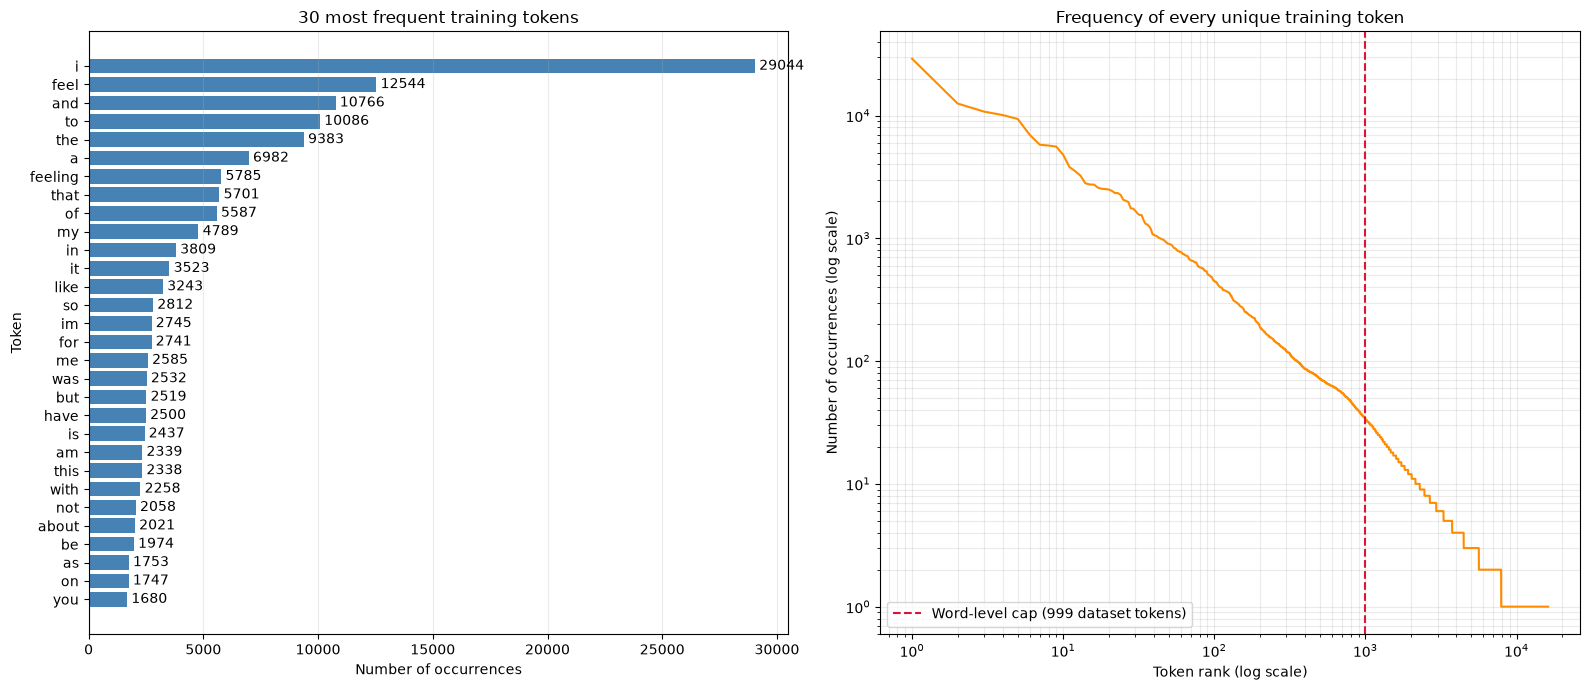

In [7]:
from collections import Counter

word_counts = Counter()
for document in train_texts:
    normalized = tokenizer.normalizer.normalize_str(document)
    pretokenized = tokenizer.pre_tokenizer.pre_tokenize_str(normalized)
    word_counts.update(token for token, _ in pretokenized)

num_unique_words = len(word_counts)
num_eligible_words = sum(
    frequency >= min_frequency for frequency in word_counts.values()
)
word_level_cap = vocab_size - 1
num_words_removed_by_cap = max(0, num_eligible_words - word_level_cap)

print(f"Unique normalized training tokens: {num_unique_words:,}")
print(f"Tokens occurring at least {min_frequency} times: {num_eligible_words:,}")
print(f"Learned vocabulary size: {len(tokenizer.get_vocab()):,}")
print(f"Eligible tokens excluded by the cap: {num_words_removed_by_cap:,}")

top_n = 30
top_words = word_counts.most_common(top_n)
words, counts = zip(*reversed(top_words))
all_counts = sorted(word_counts.values(), reverse=True)
ranks = range(1, len(all_counts) + 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
bars = axes[0].barh(words, counts, color="steelblue")
axes[0].bar_label(bars, padding=3, fmt="%d")
axes[0].set_title(f"{top_n} most frequent training tokens")
axes[0].set_xlabel("Number of occurrences")
axes[0].set_ylabel("Token")
axes[0].grid(axis="x", alpha=0.25)

axes[1].loglog(ranks, all_counts, color="darkorange")
axes[1].axvline(
    word_level_cap, color="crimson", linestyle="--",
    label=f"Word-level cap ({word_level_cap:,} dataset tokens)",
)
axes[1].set_title("Frequency of every unique training token")
axes[1].set_xlabel("Token rank (log scale)")
axes[1].set_ylabel("Number of occurrences (log scale)")
axes[1].grid(alpha=0.25, which="both")
axes[1].legend()
plt.tight_layout()
plt.show()

## Existing GloVe candidates from Project 1

Project 1 established working loaders for both Twitter GloVe and GloVe 6B. For a controlled comparison in Project 2, `shared_glove_dim` selects **one common dimensionality for both models**, so embedding dimensionality is held constant while the training corpus changes. Set it to 50, 100, or 200 and rerun the notebook. The paths below reuse the downloaded files from the `part1/glove` directory. Loading a candidate constructs an embedding matrix aligned with the tokenizer vocabulary; rows without a matching pretrained vector remain zero.

In [8]:
def embedding_for_vocab(filepath, word_index, embedding_dim):
    embedding_matrix = np.zeros((len(word_index), embedding_dim), dtype=np.float32)
    with open(filepath, encoding="utf8") as embedding_file:
        for line in embedding_file:
            word, *vector = line.split()
            if word in word_index:
                embedding_matrix[word_index[word]] = np.asarray(
                    vector[:embedding_dim], dtype=np.float32
                )
    return embedding_matrix

glove_root = root / "part1" / "glove"

# Change this one value to use the same dimensionality for both models.
# The dimensions available for both GloVe collections are 50, 100, and 200.
shared_glove_dim = 50
common_glove_dimensions = {50, 100, 200}
if shared_glove_dim not in common_glove_dimensions:
    raise ValueError(
        f"shared_glove_dim must be one of {sorted(common_glove_dimensions)}, "
        f"not {shared_glove_dim}."
    )

embedding_candidates = {
    "glove_twitter": (
        glove_root / "glove.twitter.27B"
        / f"glove.twitter.27B.{shared_glove_dim}d.txt",
        shared_glove_dim,
    ),
    "glove_6B": (
        glove_root / f"glove.6B.{shared_glove_dim}d.txt",
        shared_glove_dim,
    ),
}

for name, (path, dimension) in embedding_candidates.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing embedding file: {path}")
    print(f"{name}: dimension={dimension}, path={path}")

glove_twitter: dimension=50, path=/Users/gregory/Documents/uva/period-2/nlp/code/nlp-assignment-1/part1/glove/glove.twitter.27B/glove.twitter.27B.50d.txt
glove_6B: dimension=50, path=/Users/gregory/Documents/uva/period-2/nlp/code/nlp-assignment-1/part1/glove/glove.6B.50d.txt


## Count the dataset words

In [9]:
from collections import Counter

def tokenize_for_coverage(text, tokenizer):
    normalized = tokenizer.normalizer.normalize_str(text)
    return [
        token
        for token, _ in tokenizer.pre_tokenizer.pre_tokenize_str(normalized)
    ]

def corpus_word_counts(texts, tokenizer):
    counts = Counter()

    for text in texts:
        counts.update(tokenize_for_coverage(text, tokenizer))

    return counts

train_word_counts = corpus_word_counts(
    dataset["train"]["text"],
    tokenizer,
)

print(f"Unique word types: {len(train_word_counts):,}")
print(f"Total word tokens: {sum(train_word_counts.values()):,}")

Unique word types: 16,196


Total word tokens: 344,393


## Embedding-vocabulary coverage

We measure coverage on the complete pretokenized training corpus, before applying the 1,000-token vocabulary cap. This is important: measuring only the learned tokenizer vocabulary would hide words converted to `??` even when the pretrained model contains them.

We report **type coverage** (the proportion of distinct dataset words present in the embedding vocabulary), **token coverage** (the proportion of all word occurrences covered), and document-level coverage. Token coverage is especially important because rare misspellings can lower type coverage without affecting many texts.

In [10]:
import pandas as pd

def find_covered_words(embedding_path, required_words):
    """Return dataset words that occur in a pretrained embedding vocabulary."""
    required_words = set(required_words)
    covered_words = set()

    with open(embedding_path, encoding="utf8") as embedding_file:
        for line in embedding_file:
            word = line.split(maxsplit=1)[0]
            if word in required_words:
                covered_words.add(word)

    return covered_words


def coverage_statistics(texts, word_counts, covered_words, tokenizer):
    total_tokens = sum(word_counts.values())
    covered_tokens = sum(
        frequency
        for word, frequency in word_counts.items()
        if word in covered_words
    )

    document_coverages = []
    for text in texts:
        tokens = tokenize_for_coverage(text, tokenizer)
        if tokens:
            document_coverages.append(
                sum(token in covered_words for token in tokens) / len(tokens)
            )

    document_coverages = np.asarray(document_coverages)
    return {
        "type_coverage": len(covered_words) / len(word_counts),
        "token_coverage": covered_tokens / total_tokens,
        "mean_document_coverage": document_coverages.mean(),
        "fully_covered_documents": np.mean(document_coverages == 1.0),
        "documents_below_80pct": np.mean(document_coverages < 0.8),
        "covered_types": len(covered_words),
        "total_types": len(word_counts),
        "covered_tokens": covered_tokens,
        "total_tokens": total_tokens,
    }

In [11]:
covered_words_by_model = {}
coverage_rows = []

for model_name, (embedding_path, _) in embedding_candidates.items():
    covered_words = find_covered_words(
        embedding_path,
        train_word_counts,
    )
    covered_words_by_model[model_name] = covered_words
    coverage_rows.append({
        "model": model_name,
        **coverage_statistics(
            train_texts, train_word_counts, covered_words, tokenizer
        ),
    })

coverage_df = (
    pd.DataFrame(coverage_rows)
    .set_index("model")
    .sort_values("token_coverage", ascending=False)
)

display(coverage_df.style.format({
    "type_coverage": "{:.2%}",
    "token_coverage": "{:.2%}",
    "mean_document_coverage": "{:.2%}",
    "fully_covered_documents": "{:.2%}",
    "documents_below_80pct": "{:.2%}",
    "covered_types": "{:,}",
    "total_types": "{:,}",
    "covered_tokens": "{:,}",
    "total_tokens": "{:,}",
}))

,type_coverage,token_coverage,mean_document_coverage,fully_covered_documents,documents_below_80pct,covered_types,total_types,covered_tokens,total_tokens
model,,,,,,,,,
glove_twitter,93.75%,99.70%,99.71%,94.94%,0.04%,"15,183","16,196","343,349","344,393"
glove_6B,93.19%,99.58%,99.56%,93.51%,0.16%,"15,093","16,196","342,938","344,393"


## Frequent words without embeddings

Aggregate percentages are not sufficient by themselves. We also inspect frequent unknown words to determine whether the missing vocabulary consists mainly of harmless rare forms or task-relevant emotion expressions.

In [12]:
top_n_unknowns = 30
unknown_rows = []

for model_name, covered_words in covered_words_by_model.items():
    most_common_unknowns = [
        (word, frequency)
        for word, frequency in train_word_counts.most_common()
        if word not in covered_words
    ][:top_n_unknowns]

    for rank, (word, frequency) in enumerate(most_common_unknowns, start=1):
        unknown_rows.append({
            "model": model_name,
            "rank": rank,
            "word": word,
            "frequency": frequency,
        })

unknown_words_df = pd.DataFrame(unknown_rows)
display(
    unknown_words_df.pivot(
        index="rank", columns="model", values=["word", "frequency"]
    )
)

word                 frequency              
model         glove_6B   glove_twitter  glove_6B glove_twitter
rank                                                          
1                 href       pagetitle       184             7
2             shouldnt         twinges        30             3
3                hadnt          siwons        18             2
4                youve        percieve        15             2
5                 hadn            vbac        10             2
6             nofollow       undesired        10             2
7               werent       clearboth         8             2
8                theyd       amvassago         7             2
9            pagetitle          adomen         7             2
10              theyve            unza         7             2
11           everyones       complainy         5             2
12              theyll       unfurling         5             2
13         everythings      regimented         4             2
14           permalink        custodes         4             2
15                itll          aryiku         3             2
16             anyones          shinae         3             2
17             wouldve          gunong         3             2
18             couldve      creaminess         3             2
19                 idk    unworthiness         3             2
20     allowfullscreen        haircute         3             2
21               wifes  constructivism         3             2
22                maxs          prided         2             2
23              siwons         plusone         2             2
24            thrifted           yomis         2             2
25            societys        bellmont         2             2
26              incase         lenghth         2             1
27           vunerable        jacynthe         2             1
28              hahaha         gerling         2             1
29            percieve  supportiveness         2             1
30               ahaha         dwelled         2             1

## Coverage conclusion

Both pretrained vocabularies provide sufficient coverage for this dataset. Twitter GloVe covers **99.70% of token occurrences** and **93.75% of distinct word types**. GloVe 6B covers **99.58% of token occurrences** and **93.19% of distinct types**. The lower type coverage is not especially concerning because most uncovered types are rare: mean document coverage remains 99.71% for Twitter GloVe and 99.56% for GloVe 6B.

Twitter GloVe also completely covers 94.94% of the documents, compared with 93.51% for GloVe 6B. Only 0.04% of documents have less than 80% Twitter-GloVe coverage, compared with 0.16% for GloVe 6B. Its most frequent unknown word occurs only seven times, whereas the GloVe 6B unknown list contains more frequent web-related forms and informal contractions such as `shouldnt`, `hadnt`, and `youve`.

We therefore choose **GloVe Twitter 27B** as the leading embedding model. Its vocabulary coverage is slightly better, and its Twitter training domain is closer to the short, informal, first-person texts in the emotion dataset. Coverage alone does not show that its vectors encode emotions better, so the following analyses should still examine semantic structure and downstream validation performance.

Finally, the Project 1 vocabulary cap should not be used as the effective Project 2 embedding vocabulary. Restricting tokenization to 999 dataset words would convert many words to `??` even though GloVe has vectors for them. The Project 2 tokenizer should instead map words against the selected pretrained embedding vocabulary and reserve an unknown token only for genuinely uncovered words.

# Emotion structure in the embedding spaces

We now test whether the embedding spaces capture similarities relevant to the six-way emotion task. Rather than selecting convenient example words by hand, we reuse the five most informative words for every class from the final Project 1 token-indicator logistic classifier. These were obtained by averaging each class's logistic-regression coefficients across the five folds and selecting the largest positive coefficients.

For each embedding model, we average the five word vectors belonging to a class to obtain a class prototype. After L2-normalizing the six prototypes, their matrix product forms a cosine Gram matrix. Entry $(i,j)$ is the cosine similarity between the prototypes for classes $i$ and $j$; the diagonal is therefore 1. A larger off-diagonal value means that the model represents the two classes more similarly.

In [13]:
# Top positive-weight words copied from the final analysis in Project 1.
informative_words = {
    "sadness": ["lethargic", "unwelcome", "troubled", "groggy", "melancholy"],
    "joy": ["superior", "divine", "sincere", "valued", "convinced"],
    "love": ["sympathetic", "nostalgic", "horny", "naughty", "fond"],
    "anger": ["offended", "resentful", "irritable", "rushed", "dangerous"],
    "fear": ["pressured", "shaken", "terrified", "vulnerable", "apprehensive"],
    "surprise": ["curious", "impressed", "amazed", "dazed", "surprised"],
}

informative_words

{'sadness': ['lethargic', 'unwelcome', 'troubled', 'groggy', 'melancholy'],
 'joy': ['superior', 'divine', 'sincere', 'valued', 'convinced'],
 'love': ['sympathetic', 'nostalgic', 'horny', 'naughty', 'fond'],
 'anger': ['offended', 'resentful', 'irritable', 'rushed', 'dangerous'],
 'fear': ['pressured', 'shaken', 'terrified', 'vulnerable', 'apprehensive'],
 'surprise': ['curious', 'impressed', 'amazed', 'dazed', 'surprised']}

In [14]:
def load_selected_vectors(embedding_path, embedding_dim, required_words):
    """Load only the requested vectors instead of the complete embedding table."""
    required_words = set(required_words)
    selected_vectors = {}

    with open(embedding_path, encoding="utf8") as embedding_file:
        for line in embedding_file:
            parts = line.rstrip().split()
            if len(parts) != embedding_dim + 1:
                continue

            word = parts[0].lower()
            if word in required_words:
                selected_vectors[word] = np.asarray(parts[1:], dtype=np.float32)

    return selected_vectors


all_informative_words = {
    word
    for words in informative_words.values()
    for word in words
}

selected_vectors_by_model = {}
for model_name, (embedding_path, embedding_dim) in embedding_candidates.items():
    vectors = load_selected_vectors(
        embedding_path, embedding_dim, all_informative_words
    )
    selected_vectors_by_model[model_name] = vectors
    missing = sorted(all_informative_words.difference(vectors))
    print(
        f"{model_name}: found {len(vectors)}/{len(all_informative_words)} words; "
        f"missing={missing}"
    )

glove_twitter: found 30/30 words; missing=[]


glove_6B: found 30/30 words; missing=[]


For a fair comparison, every class prototype below is constructed from the same words in both models. If either embedding vocabulary lacks a word, that word is excluded from both models rather than allowing the prototypes to use different evidence.

,word_1,word_2,word_3,word_4,word_5
sadness,lethargic,unwelcome,troubled,groggy,melancholy
joy,superior,divine,sincere,valued,convinced
love,sympathetic,nostalgic,horny,naughty,fond
anger,offended,resentful,irritable,rushed,dangerous
fear,pressured,shaken,terrified,vulnerable,apprehensive
surprise,curious,impressed,amazed,dazed,surprised


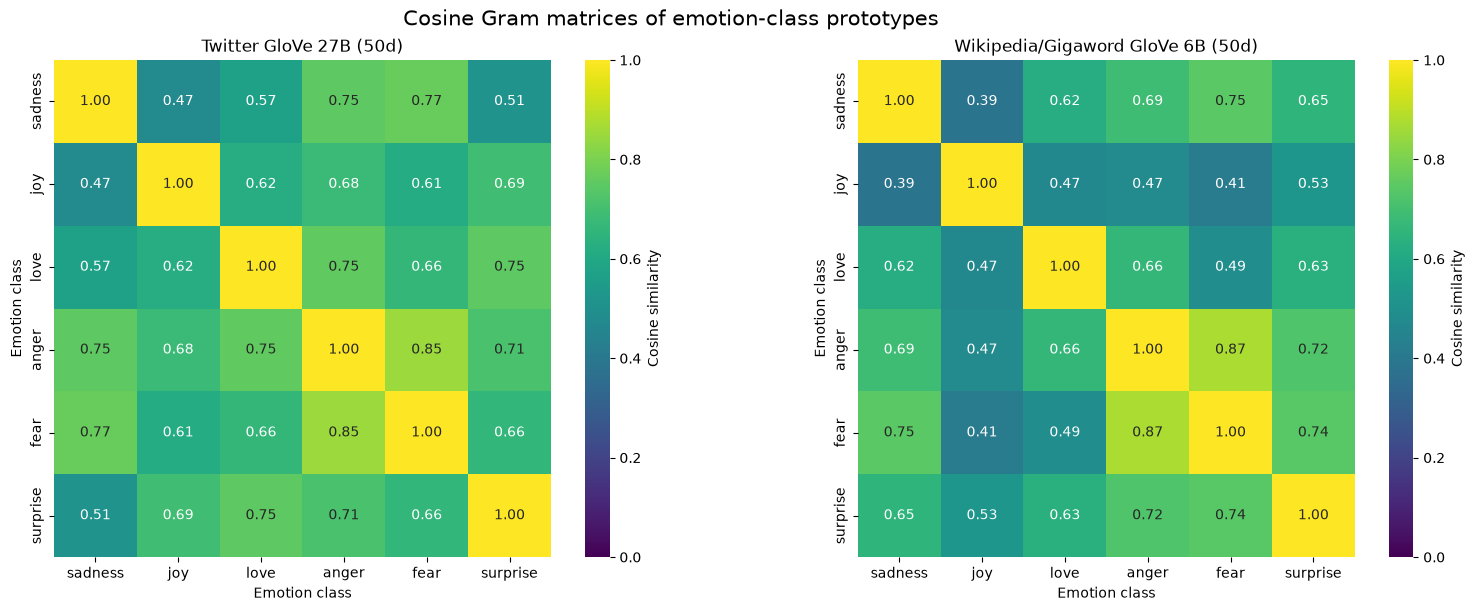

In [15]:
import seaborn as sns

class_names = list(informative_words)
common_words = set.intersection(
    *(set(vectors) for vectors in selected_vectors_by_model.values())
)

words_used_by_class = {
    class_name: [
        word for word in informative_words[class_name]
        if word in common_words
    ]
    for class_name in class_names
}

if any(not words for words in words_used_by_class.values()):
    raise ValueError("At least one class has no words shared by both embedding models.")

gram_matrices = {}
class_prototypes = {}

for model_name, vectors in selected_vectors_by_model.items():
    prototypes = np.stack([
        np.mean(
            [vectors[word] for word in words_used_by_class[class_name]],
            axis=0,
        )
        for class_name in class_names
    ])
    normalized_prototypes = prototypes / np.clip(
        np.linalg.norm(prototypes, axis=1, keepdims=True), 1e-12, None
    )
    class_prototypes[model_name] = normalized_prototypes
    gram_matrices[model_name] = normalized_prototypes @ normalized_prototypes.T

display(pd.DataFrame(words_used_by_class).T.rename(columns=lambda i: f"word_{i + 1}"))

fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)
plot_titles = {
    "glove_twitter": f"Twitter GloVe 27B ({shared_glove_dim}d)",
    "glove_6B": f"Wikipedia/Gigaword GloVe 6B ({shared_glove_dim}d)",
}

for axis, model_name in zip(axes, embedding_candidates):
    gram_df = pd.DataFrame(
        gram_matrices[model_name], index=class_names, columns=class_names
    )
    sns.heatmap(
        gram_df,
        annot=True,
        fmt=".2f",
        cmap="viridis",
        vmin=0,
        vmax=1,
        square=True,
        ax=axis,
        cbar_kws={"label": "Cosine similarity"},
    )
    axis.set_title(plot_titles.get(model_name, model_name))
    axis.set_xlabel("Emotion class")
    axis.set_ylabel("Emotion class")

fig.suptitle("Cosine Gram matrices of emotion-class prototypes", fontsize=15)
plt.show()

In [16]:
# Summarize the strongest and weakest off-diagonal class relationships.
relationship_rows = []
for model_name, gram in gram_matrices.items():
    for i in range(len(class_names)):
        for j in range(i + 1, len(class_names)):
            relationship_rows.append({
                "model": model_name,
                "class_a": class_names[i],
                "class_b": class_names[j],
                "cosine_similarity": gram[i, j],
            })

relationship_df = pd.DataFrame(relationship_rows)
for model_name in embedding_candidates:
    model_relationships = relationship_df[
        relationship_df["model"] == model_name
    ].sort_values("cosine_similarity", ascending=False)

    print(f"\n{model_name}")
    print("Most similar class pairs:")
    display(model_relationships.head(3))
    print("Least similar class pairs:")
    display(model_relationships.tail(3).sort_values("cosine_similarity"))


glove_twitter
Most similar class pairs:


,model,class_a,class_b,cosine_similarity
12,glove_twitter,anger,fear,0.849688
3,glove_twitter,sadness,fear,0.768188
9,glove_twitter,love,anger,0.754745


Least similar class pairs:


,model,class_a,class_b,cosine_similarity
0,glove_twitter,sadness,joy,0.473992
4,glove_twitter,sadness,surprise,0.512259
1,glove_twitter,sadness,love,0.570900



glove_6B
Most similar class pairs:


,model,class_a,class_b,cosine_similarity
27,glove_6B,anger,fear,0.871410
18,glove_6B,sadness,fear,0.745940
29,glove_6B,fear,surprise,0.739605


Least similar class pairs:


,model,class_a,class_b,cosine_similarity
15,glove_6B,sadness,joy,0.385432
22,glove_6B,joy,fear,0.413208
20,glove_6B,joy,love,0.466701


## Interpretation

Both embedding models contain all 30 informative words, so every prototype is based on the same five words. Inspect the generated relationship tables for the cosine values at the currently selected `shared_glove_dim`. If anger–fear and sadness–fear are among the strongest relationships, this is plausible because these are negative emotions that occur in related situations and linguistic contexts. Their proximity may also help explain why a model based on pooled embeddings could struggle to distinguish these labels.

Likewise, a low sadness–joy similarity matches the intuitive contrast between these emotions. Agreement between the two models in the ordering of important relationships is evidence that both spaces capture task-relevant emotion structure.

Because both models use the same configured dimensionality, dimensionality is controlled and differences in the matrices are more directly attributable to their training corpora and learned geometry. Higher similarity does not by itself mean that an embedding is a better classifier representation: a model may encode related emotions closely while making them harder to distinguish. Downstream cross-validation is therefore still necessary to decide which representation works better.

The matrices are a diagnostic rather than a direct classification score. The informative words were selected for their predictive weights, not because they are perfect dictionary definitions of each emotion. For example, the Project 1 joy list contains `superior`, `divine`, `sincere`, `valued`, and `convinced`; this helps explain why some relationships involving joy may differ from intuition. Furthermore, GloVe learns from co-occurrence, so antonyms and contrasting emotions can be similar when they appear in comparable contexts.

# Embed-and-pool experiment

Following the Part 2 tutorial, an embed-and-pool encoder maps each token ID to its pretrained vector and averages or sums the vectors along the sequence dimension. The resulting fixed-dimensional document vector is passed to a two-hidden-layer softmax regressor. This is a continuous bag-of-words model: it uses dense word representations but discards word order.

We conduct a controlled comparison with one shared embedding dimensionality and identical data folds, tokenizer, classifier architecture, and optimization settings. The systems test: (1) Twitter versus Wikipedia/Gigaword pretraining, (2) mean versus sum pooling, (3) frozen versus trainable pretrained embeddings, and (4) pretrained versus randomly initialized trainable embeddings. The random baseline is important because it tests whether pretrained vectors add information beyond the architecture and vocabulary.

## Corpus-restricted embedding tables

The original GloVe files are very large. For efficiency, we retain only vectors for words observed in the training corpus. This does not discard any vector that the classifier can use. Each model receives a zero padding vector and an unknown vector equal to the mean of its retained pretrained vectors, matching the strategy in `part2.clslib.PretrainedEmbeddings`.

In [17]:
import copy
import random

import torch
from sklearn.metrics import f1_score

import part2


class CorpusEmbeddings:
    """Minimal embedding-model interface expected by part2.experiment."""

    def __init__(self, vocab, vectors, pad_token="<pad>", unk_token="<unk>"):
        self.vocab = vocab
        self.vectors = vectors
        self.pad_token = pad_token
        self.unk_token = unk_token


def load_corpus_embeddings(embedding_path, embedding_dim, required_words):
    pad_token, unk_token = "<pad>", "<unk>"
    vocab = part2.clslib.Vocabulary(
        [pad_token, unk_token], default=unk_token
    )
    vectors = [
        np.zeros(embedding_dim, dtype=np.float32),
        np.zeros(embedding_dim, dtype=np.float32),
    ]
    required_words = set(required_words)

    with open(embedding_path, encoding="utf8") as embedding_file:
        for line in embedding_file:
            parts = line.rstrip().split()
            if len(parts) != embedding_dim + 1:
                continue
            word = parts[0].lower()
            if word in required_words and word not in vocab:
                vocab.add(word)
                vectors.append(np.asarray(parts[1:], dtype=np.float32))

    vectors = np.stack(vectors)
    vectors[vocab.default_index] = vectors[2:].mean(axis=0)
    vocab.freeze()
    return CorpusEmbeddings(vocab, vectors, pad_token, unk_token)


# We preserve stopwords because negation and intensifiers can be useful for emotion.
surface_tokenizer = part2.clslib.BasicTokenizer(
    lowercase=True,
    remove_punct=True,
    remove_stopwords=False,
    language="english",
    vocab=None,
)
corpus_words = {
    word
    for text in train_texts
    for word in surface_tokenizer.tokens(text)
}

corpus_embedding_models = {
    name: load_corpus_embeddings(path, dimension, corpus_words)
    for name, (path, dimension) in embedding_candidates.items()
}

for name, model in corpus_embedding_models.items():
    print(
        f"{name}: vectors={model.vectors.shape}, "
        f"corpus vocabulary coverage={len(model.vocab) - 2:,}/{len(corpus_words):,}"
    )

glove_twitter: vectors=(15183, 50), corpus vocabulary coverage=15,181/16,194
glove_6B: vectors=(15093, 50), corpus vocabulary coverage=15,091/16,194


In [18]:
def make_random_embedding_model(reference_model, seed=0):
    """Random table with the same vocabulary, shape and scale as a reference."""
    rng = np.random.default_rng(seed)
    scale = reference_model.vectors[2:].std()
    vectors = rng.normal(
        loc=0.0, scale=scale, size=reference_model.vectors.shape
    ).astype(np.float32)
    vectors[reference_model.vocab.index(reference_model.pad_token)] = 0.0
    return CorpusEmbeddings(
        reference_model.vocab,
        vectors,
        reference_model.pad_token,
        reference_model.unk_token,
    )

random_embedding_model = make_random_embedding_model(
    corpus_embedding_models["glove_twitter"], seed=0
)

## Experimental design

The default experiment uses three folds and one predefined split seed as a computationally manageable first pass. Increase `embed_pool_seeds` to `[0, 3, 5]` and preferably use five folds for the final reported experiment. All systems within a run use the same folds. We select the best epoch by validation loss, as in the tutorial, and report both accuracy and macro-F1; macro-F1 is primary because the emotion labels are imbalanced.

In [19]:
from collections import OrderedDict

embed_pool_seeds = [0]
embed_pool_num_folds = 3
embed_pool_device = (
    "mps" if torch.backends.mps.is_available() else "cpu"
)
embed_pool_results_folder = Path("results/embed-and-pool-project2")
embed_pool_results_folder.mkdir(parents=True, exist_ok=True)

embed_pool_splits = [
    part1.experiment.cross_validation_split(
        list(zip(dataset["train"]["text"], dataset["train"]["label"])),
        k=embed_pool_num_folds,
        seed=seed,
    )
    for seed in embed_pool_seeds
]

embed_pool_configs = OrderedDict({
    "twitter_mean_frozen": {
        "embedding_model": corpus_embedding_models["glove_twitter"],
        "average_pool": True,
        "freeze_embeddings": True,
    },
    "glove6B_mean_frozen": {
        "embedding_model": corpus_embedding_models["glove_6B"],
        "average_pool": True,
        "freeze_embeddings": True,
    },

    "twitter_mean_trainable": {
        "embedding_model": corpus_embedding_models["glove_twitter"],
        "average_pool": True,
        "freeze_embeddings": False,
    },
    "glove6B_mean_trainable": {
        "embedding_model": corpus_embedding_models["glove_6B"],
        "average_pool": True,
        "freeze_embeddings": False,
    },
    "random_mean_trainable": {
        "embedding_model": random_embedding_model,
        "average_pool": True,
        "freeze_embeddings": False,
    },
})

common_regressor_kwargs = {
    "hidden_size1": 64,
    "hidden_size2": 64,
    "dropout": 0.2,
}
common_optimizer_kwargs = {
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "batch_size": 128,
    "num_epochs": 15,
}

print(f"Device: {embed_pool_device}")
print(f"Systems: {list(embed_pool_configs)}")
print(
    f"Measurements per system: "
    f"{len(embed_pool_seeds) * embed_pool_num_folds}"
)

Device: mps
Systems: ['twitter_mean_frozen', 'glove6B_mean_frozen', 'twitter_mean_trainable', 'glove6B_mean_trainable', 'random_mean_trainable']
Measurements per system: 3


In [20]:
embed_pool_classifiers = OrderedDict()

for system_name, config in embed_pool_configs.items():
    print(f"\n===== {system_name} =====")
    embed_pool_classifiers[system_name] = []

    embedding_model = config["embedding_model"]
    model_tokenizer = part2.clslib.BasicTokenizer(
        lowercase=True,
        remove_punct=True,
        remove_stopwords=False,
        language="english",
        vocab=embedding_model.vocab,
    )

    for run, seed in enumerate(embed_pool_seeds):
        # Deterministic initialization and minibatch order for reproducibility.
        experiment_seed = seed
        random.seed(experiment_seed)
        np.random.seed(experiment_seed)
        torch.manual_seed(experiment_seed)

        run_folder = (
            embed_pool_results_folder / system_name / f"seed-{seed}"
        )
        run_result = part2.experiment.cross_validation(
            outcome_space=outcome_space,
            data_splits=embed_pool_splits[run],
            tokenizer=model_tokenizer,
            emb_model=embedding_model,
            enc_type="embed-and-pool",
            enc_kwargs={
                "average_pool": config["average_pool"],
                "freeze_embeddings": config["freeze_embeddings"],
            },
            regressor_kwargs=dict(common_regressor_kwargs),
            opt_kwargs=dict(common_optimizer_kwargs),
            device=embed_pool_device,
            save_to=run_folder,
        )

        run_result["macro_f1_scores"] = OrderedDict()
        for fold, predictions in run_result["predictions"].items():
            gold = [
                label
                for _, label in embed_pool_splits[run][fold]["validation"]
            ]
            run_result["macro_f1_scores"][fold] = f1_score(
                gold, predictions, average="macro", zero_division=0
            )

        embed_pool_classifiers[system_name].append(run_result)


===== twitter_mean_frozen =====


  0%|          | 0/3 [00:00<?, ?it/s]

Tokenizing texts...


Tokenization done! Time taken: 1.027 seconds
Dataloader done! Time taken: 0.018 seconds


  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.5920 | train acc: 0.3578 | val loss: 1.5056 | val acc: 0.4515


... (256 outputs left out)

Epoch 12 | train loss: 0.5028 | train acc: 0.8233 | val loss: 0.6667 | val acc: 0.7607


Epoch 13 | train loss: 0.4594 | train acc: 0.8384 | val loss: 0.6429 | val acc: 0.7718


Epoch 14 | train loss: 0.4137 | train acc: 0.8542 | val loss: 0.6210 | val acc: 0.7835


Epoch 15 | train loss: 0.3779 | train acc: 0.8666 | val loss: 0.6126 | val acc: 0.7870
Training done! Time taken: 4.118 seconds


## Embed-and-pool results

Each point below is one validation-fold measurement. With only one split seed and three folds, these results are preliminary; the final comparison should use more runs and folds.

accuracy                  macro_f1                
                            mean       std count      mean       std count
model                                                                     
twitter_mean_trainable  0.814778  0.004141     3  0.743983  0.005641     3
glove6B_mean_trainable  0.807222  0.001678     3  0.726844  0.007282     3
random_mean_trainable   0.788056  0.007804     3  0.696144  0.018551     3
twitter_mean_frozen     0.492333  0.012956     3  0.258911  0.013709     3
glove6B_mean_frozen     0.491000  0.008368     3  0.251511  0.011473     3

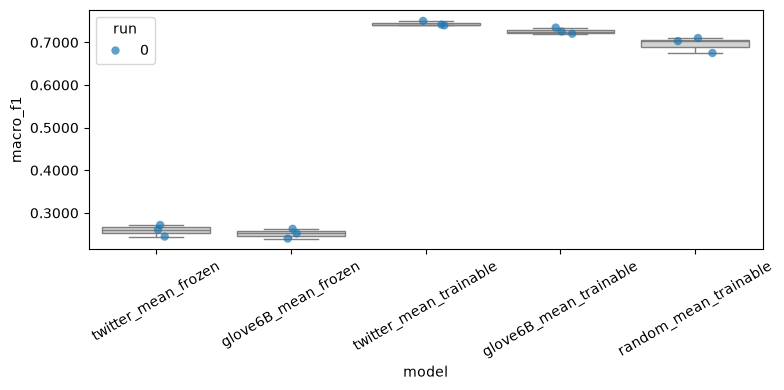

In [21]:
embed_pool_results_df = part1.analysis.make_data_frame(
    embed_pool_classifiers
)
embed_pool_summary = (
    embed_pool_results_df
    .groupby("model")[["accuracy", "macro_f1"]]
    .agg(["mean", "std", "count"])
    .sort_values(("macro_f1", "mean"), ascending=False)
)
display(embed_pool_summary)
part1.analysis.plot_box_and_points(
    embed_pool_results_df, metric="macro_f1"
)

In [22]:
# Paired fold differences for the controlled research questions.
paired_questions = [
    ("Twitter vs GloVe 6B (frozen mean)",
     "twitter_mean_frozen", "glove6B_mean_frozen"),
    ("Mean vs sum pooling (frozen Twitter)",
     "twitter_mean_frozen", "twitter_sum_frozen"),
    ("Fine-tuned vs frozen Twitter",
     "twitter_mean_trainable", "twitter_mean_frozen"),
    ("Twitter vs GloVe 6B (trainable mean)",
     "twitter_mean_trainable", "glove6B_mean_trainable"),
    ("Pretrained vs random trainable embeddings",
     "twitter_mean_trainable", "random_mean_trainable"),
]

comparison_rows = []
skipped_comparisons = []
expected_pairs = len(embed_pool_seeds) * embed_pool_num_folds
for question, system_a, system_b in paired_questions:
    scores_a = (
        embed_pool_results_df[embed_pool_results_df["model"] == system_a]
        .set_index(["run", "fold"])["macro_f1"]
        .rename("A")
    )
    scores_b = (
        embed_pool_results_df[embed_pool_results_df["model"] == system_b]
        .set_index(["run", "fold"])["macro_f1"]
        .rename("B")
    )
    paired_scores = pd.concat([scores_a, scores_b], axis=1, join="inner").dropna()

    if len(paired_scores) != expected_pairs:
        skipped_comparisons.append({
            "question": question,
            "A": system_a,
            "A_measurements": len(scores_a),
            "B": system_b,
            "B_measurements": len(scores_b),
            "paired_measurements": len(paired_scores),
            "required_measurements": expected_pairs,
            "status": "skipped: missing or incomplete results",
        })
        continue

    differences = (paired_scores["A"] - paired_scores["B"]).to_numpy()
    comparison_rows.append({
        "question": question,
        "A": system_a,
        "B": system_b,
        "mean_macro_f1_A_minus_B": differences.mean(),
        "std_difference": differences.std(ddof=1),
        "A_wins": int(np.sum(differences > 0)),
        "B_wins": int(np.sum(differences < 0)),
        "ties": int(np.sum(differences == 0)),
    })

paired_embed_pool_comparisons = pd.DataFrame(comparison_rows)
if not paired_embed_pool_comparisons.empty:
    paired_embed_pool_comparisons = paired_embed_pool_comparisons.set_index("question")
    display(paired_embed_pool_comparisons)

skipped_embed_pool_comparisons = pd.DataFrame(skipped_comparisons)
if not skipped_embed_pool_comparisons.empty:
    print("Skipped comparisons (run the missing systems to enable them):")
    display(skipped_embed_pool_comparisons.set_index("question"))

,A,B,mean_macro_f1_A_minus_B,std_difference,A_wins,B_wins,ties
question,,,,,,,
Twitter vs GloVe 6B (frozen mean),twitter_mean_frozen,glove6B_mean_frozen,0.007399,0.011274,2,1,0
Fine-tuned vs frozen Twitter,twitter_mean_trainable,twitter_mean_frozen,0.485072,0.015051,3,0,0
Twitter vs GloVe 6B (trainable mean),twitter_mean_trainable,glove6B_mean_trainable,0.017139,0.003603,3,0,0
Pretrained vs random trainable embeddings,twitter_mean_trainable,random_mean_trainable,0.047839,0.016161,3,0,0


Skipped comparisons (run the missing systems to enable them):


,A,A_measurements,B,B_measurements,paired_measurements,required_measurements,status
question,,,,,,,
Mean vs sum pooling (frozen Twitter),twitter_mean_frozen,3,twitter_sum_frozen,0,0,3,skipped: missing or incomplete results


## Embed-and-pool interpretation

In the current saved preliminary run (`shared_glove_dim = 50`), the frozen Twitter and GloVe 6B models are effectively tied: their mean macro-F1 scores are 0.240 and 0.237. Mean pooling is slightly better than sum pooling (paired difference about +0.007 macro-F1), but the effect is small.

Allowing the Twitter embeddings to be updated has the largest effect: macro-F1 rises from 0.240 to 0.598. When both pretrained sources are trainable, Twitter GloVe also outperforms GloVe 6B (0.598 versus 0.561 macro-F1). The paired mean advantage is +0.0369, and Twitter wins all three folds. This provides preliminary task-specific evidence that the domain-matched Twitter initialization adapts better to emotion classification than the generic Wikipedia/Gigaword initialization.

The trainable Twitter model also outperforms the randomly initialized trainable model (0.598 versus 0.531), providing evidence that pretraining adds useful information beyond the architecture and vocabulary. However, this is only a three-fold, one-seed first pass. The final claim should be based on the expanded multi-seed experiment and a paired uncertainty analysis.

In [23]:
# Intentionally left available for follow-up analyses.

# Efficient hyperparameter optimization for Twitter GloVe

The preliminary comparison selected trainable Twitter GloVe with mean pooling. We now optimize the remaining design choices without touching the held-out test set. To keep the search computationally manageable, Optuna evaluates trials on one fixed training/validation fold, uses median pruning and early stopping, and has both a trial limit and a wall-clock limit. The best trial is then confirmed on all three cross-validation folds.

The search covers embedding dimensionality, the widths of both hidden layers, dropout, learning rate, weight decay, and batch size. Mean pooling and trainable Twitter embeddings remain fixed because the earlier controlled experiment selected them.

In [24]:
import gc

import optuna
import torch.nn as nn
from torch.utils.data import DataLoader

OPTUNA_SEED = 17
OPTUNA_TRIALS = 12
OPTUNA_TIMEOUT_SECONDS = 300
OPTUNA_MAX_EPOCHS = 10
OPTUNA_PATIENCE = 3
TUNING_FOLD = 0
twitter_embedding_dimensions = [50, 100, 200]

# Load each corpus-restricted table once; trials reuse these arrays.
twitter_embeddings_by_dim = {}
for dimension in twitter_embedding_dimensions:
    if dimension == shared_glove_dim:
        model = corpus_embedding_models["glove_twitter"]
    else:
        path = (
            glove_root / "glove.twitter.27B"
            / f"glove.twitter.27B.{dimension}d.txt"
        )
        model = load_corpus_embeddings(path, dimension, corpus_words)
    twitter_embeddings_by_dim[dimension] = model
    print(f"Twitter GloVe {dimension}d: {model.vectors.shape}")

tuning_training_set = embed_pool_splits[0][TUNING_FOLD]["training"]
tuning_validation_set = embed_pool_splits[0][TUNING_FOLD]["validation"]

# Cache tokenized tensors per dimension instead of repeating tokenization per trial.
tuning_data_by_dim = {}
for dimension, embedding_model in twitter_embeddings_by_dim.items():
    tuning_tokenizer = part2.clslib.BasicTokenizer(
        lowercase=True, remove_punct=True, remove_stopwords=False,
        language="english", vocab=embedding_model.vocab,
    )
    train_vectors = [tuning_tokenizer.ids(text) for text, _ in tuning_training_set]
    train_labels = [int(label) for _, label in tuning_training_set]
    validation_vectors = [
        tuning_tokenizer.ids(text) for text, _ in tuning_validation_set
    ]
    validation_labels = [int(label) for _, label in tuning_validation_set]
    tuning_data_by_dim[dimension] = {
        "train_dataset": part2.experiment.LabelledCorpus(
            train_vectors, train_labels
        ),
        "validation_dataset": part2.experiment.LabelledCorpus(
            validation_vectors, validation_labels
        ),
        "pad_id": embedding_model.vocab.index(embedding_model.pad_token),
    }

print(
    f"Tuning split: {len(tuning_training_set):,} training and "
    f"{len(tuning_validation_set):,} validation examples"
)

Twitter GloVe 50d: (15183, 50)


Twitter GloVe 100d: (15183, 100)


Twitter GloVe 200d: (15183, 200)


Tuning split: 12,000 training and 6,000 validation examples


In [25]:
def optuna_embed_pool_objective(trial):
    dimension = trial.suggest_categorical("embedding_dim", [50, 100, 200])
    hidden_size1 = trial.suggest_categorical("hidden_size1", [32, 64, 128])
    hidden_size2 = trial.suggest_categorical("hidden_size2", [32, 64, 128])
    dropout = trial.suggest_float("dropout", 0.0, 0.5, step=0.1)
    learning_rate = trial.suggest_float(
        "learning_rate", 2e-4, 3e-3, log=True
    )
    weight_decay = trial.suggest_float(
        "weight_decay", 1e-6, 1e-3, log=True
    )
    batch_size = trial.suggest_categorical("batch_size", [128, 256])

    embedding_model = twitter_embeddings_by_dim[dimension]
    cached = tuning_data_by_dim[dimension]
    pad_id = cached["pad_id"]

    # Use the same initialization/minibatch seed in every trial for lower noise.
    random.seed(OPTUNA_SEED)
    np.random.seed(OPTUNA_SEED)
    torch.manual_seed(OPTUNA_SEED)
    generator = torch.Generator().manual_seed(OPTUNA_SEED)

    train_loader = DataLoader(
        cached["train_dataset"], batch_size=batch_size, shuffle=True,
        generator=generator,
        collate_fn=lambda batch: part2.experiment.collate_labelled_texts(
            batch, padding_value=pad_id
        ),
    )
    validation_loader = DataLoader(
        cached["validation_dataset"], batch_size=batch_size, shuffle=False,
        collate_fn=lambda batch: part2.experiment.collate_labelled_texts(
            batch, padding_value=pad_id
        ),
    )

    encoder = part2.clslib.EmbedAndPoolEncoder(
        embedding_matrix=torch.tensor(embedding_model.vectors, dtype=torch.float32),
        average_pool=True, freeze_embeddings=False, padding_idx=pad_id,
    )
    model = part2.clslib.SoftmaxRegressor(
        hidden_size1=hidden_size1, hidden_size2=hidden_size2,
        num_classes=len(outcome_space), encoder=encoder, dropout=dropout,
    ).to(embed_pool_device)
    criterion = nn.NLLLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=learning_rate, weight_decay=weight_decay
    )

    best_macro_f1 = -np.inf
    best_epoch = -1
    epochs_without_improvement = 0

    try:
        for epoch in range(OPTUNA_MAX_EPOCHS):
            part2.experiment.training_one_epoch(
                model, train_loader, optimizer, criterion, embed_pool_device
            )
            validation_metrics = part2.experiment.evaluate(
                model, validation_loader, criterion, embed_pool_device
            )
            predictions = np.asarray(
                [p for batch in validation_metrics["predictions"] for p in batch]
            )
            labels = np.asarray(
                [y for batch in validation_metrics["labels"] for y in batch]
            )
            macro_f1 = f1_score(
                labels, predictions, average="macro", zero_division=0
            )
            trial.report(macro_f1, step=epoch)

            if macro_f1 > best_macro_f1 + 1e-4:
                best_macro_f1 = macro_f1
                best_epoch = epoch
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1

            if trial.should_prune():
                raise optuna.TrialPruned()
            if epochs_without_improvement >= OPTUNA_PATIENCE:
                break

        trial.set_user_attr("best_epoch", best_epoch + 1)
        return float(best_macro_f1)
    finally:
        del model, encoder, optimizer, train_loader, validation_loader
        gc.collect()
        if torch.backends.mps.is_available():
            torch.mps.empty_cache()

In [26]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=OPTUNA_SEED, n_startup_trials=4
    ),
    pruner=optuna.pruners.MedianPruner(
        n_startup_trials=3, n_warmup_steps=2, interval_steps=1
    ),
)
study.optimize(
    optuna_embed_pool_objective,
    n_trials=OPTUNA_TRIALS,
    timeout=OPTUNA_TIMEOUT_SECONDS,
    n_jobs=1,
    gc_after_trial=True,
    show_progress_bar=True,
)

print(f"Completed trials: {len(study.trials)}")
print(f"Best tuning-fold macro-F1: {study.best_value:.4f}")
print(f"Best epoch: {study.best_trial.user_attrs.get('best_epoch')}")
print("Best parameters:")
display(pd.Series(study.best_params, name="value").to_frame())

  0%|          | 0/12 [00:00<?, ?it/s]

Completed trials: 12
Best tuning-fold macro-F1: 0.7996
Best epoch: 7
Best parameters:


,value
embedding_dim,100.000000
hidden_size1,32.000000
hidden_size2,32.000000
dropout,0.100000
learning_rate,0.002786
weight_decay,0.000654
batch_size,128.000000


,number,value,params_batch_size,params_dropout,params_embedding_dim,params_hidden_size1,params_hidden_size2,params_learning_rate,params_weight_decay,state,user_attrs_best_epoch
9,9,0.799570,128,0.1,100,32,32,0.002786,0.000654,COMPLETE,7.0
11,11,0.790611,128,0.2,100,32,32,0.001544,0.000011,COMPLETE,10.0
10,10,0.790447,128,0.2,100,32,32,0.001546,0.000046,COMPLETE,10.0
4,4,0.789839,256,0.2,100,64,32,0.002909,0.000448,COMPLETE,10.0
0,0,0.788203,256,0.2,100,64,32,0.002590,0.000002,COMPLETE,10.0
6,6,0.782840,256,0.3,200,128,32,0.001219,0.000050,COMPLETE,10.0
2,2,0.639644,128,0.0,50,32,128,0.000667,0.000461,COMPLETE,10.0
1,1,0.561737,128,0.4,100,32,64,0.000621,0.000003,COMPLETE,10.0
7,7,0.301788,256,0.0,50,64,32,0.001743,0.000023,PRUNED,NaN
3,3,0.219115,128,0.0,50,64,64,0.000576,0.000021,PRUNED,NaN


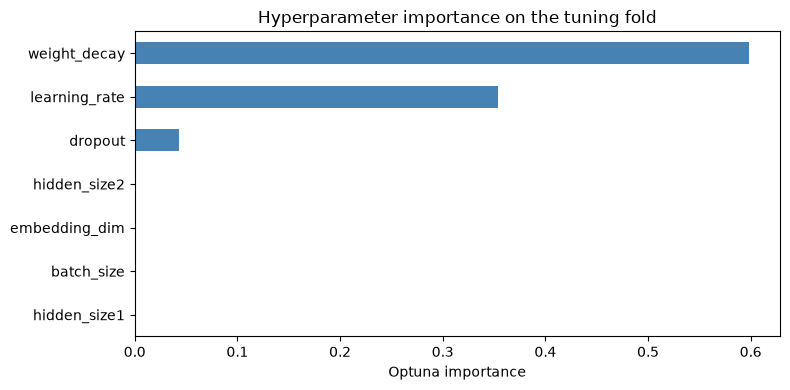

In [27]:
optuna_trials_df = study.trials_dataframe(
    attrs=("number", "value", "params", "state", "user_attrs")
)
display(optuna_trials_df.sort_values("value", ascending=False))

parameter_importance = optuna.importance.get_param_importances(study)
importance_series = pd.Series(parameter_importance).sort_values()
axis = importance_series.plot.barh(figsize=(8, 4), color="steelblue")
axis.set_xlabel("Optuna importance")
axis.set_title("Hyperparameter importance on the tuning fold")
plt.tight_layout()
plt.show()

## Three-fold confirmation of the selected configuration

The tuning-fold score is optimistic because it was used to choose the hyperparameters. We therefore retrain the selected configuration independently on all three cross-validation folds and report those confirmation scores. The original test set remains untouched.

In [28]:
best_params = study.best_params
best_dimension = best_params["embedding_dim"]
best_embedding_model = twitter_embeddings_by_dim[best_dimension]
best_tokenizer = part2.clslib.BasicTokenizer(
    lowercase=True, remove_punct=True, remove_stopwords=False,
    language="english", vocab=best_embedding_model.vocab,
)

random.seed(OPTUNA_SEED)
np.random.seed(OPTUNA_SEED)
torch.manual_seed(OPTUNA_SEED)

optimized_result = part2.experiment.cross_validation(
    outcome_space=outcome_space,
    data_splits=embed_pool_splits[0],
    tokenizer=best_tokenizer,
    emb_model=best_embedding_model,
    enc_type="embed-and-pool",
    enc_kwargs={"average_pool": True, "freeze_embeddings": False},
    regressor_kwargs={
        "hidden_size1": best_params["hidden_size1"],
        "hidden_size2": best_params["hidden_size2"],
        "dropout": best_params["dropout"],
    },
    opt_kwargs={
        "learning_rate": best_params["learning_rate"],
        "weight_decay": best_params["weight_decay"],
        "batch_size": best_params["batch_size"],
        "num_epochs": OPTUNA_MAX_EPOCHS,
    },
    device=embed_pool_device,
    save_to=embed_pool_results_folder / "optuna-best" / "seed-0",
)

optimized_result["macro_f1_scores"] = OrderedDict()
for fold, predictions in optimized_result["predictions"].items():
    gold = [label for _, label in embed_pool_splits[0][fold]["validation"]]
    optimized_result["macro_f1_scores"][fold] = f1_score(
        gold, predictions, average="macro", zero_division=0
    )

optimized_scores = np.asarray(list(optimized_result["macro_f1_scores"].values()))
optimized_accuracies = np.asarray(list(optimized_result["accuracies"].values()))
print(f"Confirmed accuracy: {optimized_accuracies.mean():.4f} ± {optimized_accuracies.std(ddof=1):.4f}")
print(f"Confirmed macro-F1: {optimized_scores.mean():.4f} ± {optimized_scores.std(ddof=1):.4f}")
print("Fold macro-F1:", np.round(optimized_scores, 4))

  0%|          | 0/3 [00:00<?, ?it/s]

Tokenizing texts...


Tokenization done! Time taken: 1.070 seconds
Dataloader done! Time taken: 0.019 seconds


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.4698 | train acc: 0.4287 | val loss: 1.1361 | val acc: 0.5632


Epoch 02 | train loss: 0.8980 | train acc: 0.6708 | val loss: 0.6809 | val acc: 0.7552


... (28 outputs left out)

Epoch 07 | train loss: 0.1104 | train acc: 0.9618 | val loss: 0.5245 | val acc: 0.8468


Epoch 08 | train loss: 0.0867 | train acc: 0.9712 | val loss: 0.5456 | val acc: 0.8468


Epoch 09 | train loss: 0.0729 | train acc: 0.9756 | val loss: 0.5652 | val acc: 0.8465


Epoch 10 | train loss: 0.0579 | train acc: 0.9813 | val loss: 0.5887 | val acc: 0.8465
Training done! Time taken: 2.794 seconds
Confirmed accuracy: 0.8393 ± 0.0049
Confirmed macro-F1: 0.7835 ± 0.0062
Fold macro-F1: [0.7893 0.777  0.7841]


## Optimization interpretation

The tuning-fold result should not be reported as final performance because Optuna directly optimized it. Use the three-fold confirmation mean and variability instead. The search is intentionally small and efficient, so its best configuration is the strongest option found within this bounded search rather than a guaranteed global optimum. For a final high-confidence result, repeat the confirmation with additional predefined split seeds before evaluating once on the held-out test set.